# Language Identification for Indian Languages (IndicCorp v2)
### Introduction to Large Language Models — Assignment 1

This notebook builds a language identification (LID) system for 23 Indian languages using the
[IndicCorp v2](https://huggingface.co/datasets/ai4bharat/IndicCorpV2) corpus.

**Pipeline**
1. Download 1000 sentences per language from IndicCorp v2 and cache them as Parquet (so we never
   have to re-download).
2. Split each language's 1000 sentences into train/val/test (80/10/10, stratified).
3. Build a **from-scratch** TF-IDF vectorizer using word unigrams+bigrams and character 2/3/4-grams
   (no `sklearn` feature-extraction classes).
4. Build a **from-scratch** multinomial (softmax) logistic regression classifier (no
   `sklearn.linear_model`).
5. Evaluate with a **from-scratch** macro-F1 implementation (no `sklearn.metrics`).

No `sklearn` classes are used anywhere in this notebook — only `numpy`/`scipy` for numerical
computation, `pandas`/`pyarrow` for I/O, and the HuggingFace `datasets` library to stream the
corpus.


## 0. Setup

In [1]:
# Run once. If these are already installed in your environment you can skip/comment this out.
# %pip install -q datasets huggingface_hub pandas pyarrow numpy scipy regex tqdm matplotlib


In [ ]:
import os
import re
import json
import time
import pickle
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from scipy import sparse
import regex  # supports \p{L} / \p{M} unicode property classes (stdlib `re` does not)
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from datasets import load_dataset

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DATA_CACHE_DIR = "data_cache"      # per-language raw sentence cache (parquet)
SPLITS_DIR = "splits"              # final train/val/test parquet files
ARTIFACTS_DIR = "artifacts"        # trained model / vectorizer artifacts
for d in (DATA_CACHE_DIR, SPLITS_DIR, ARTIFACTS_DIR):
    os.makedirs(d, exist_ok=True)

SENTENCES_PER_LANG = random.randint(500, 1500)   # as required by the assignment
MIN_WORDS_PER_SENT = 3      # drop very short "sentences" (usually noise/headers)
MAX_WORDS_PER_SENT = 60     # drop very long ones (usually mis-split paragraphs)


/opt/anaconda3/envs/nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Language / script configuration

The mapping below comes directly from the dataset's HuggingFace config (`indiccorp_v2`). Each
entry is a HF **split name** of the form `<lang>_<Script>` (ISO 639-3 code + ISO 15924 script
code), except for `khasi` and `santhali` which don't carry a script suffix in the repo.


In [3]:
# split_name -> (lang_code, script)   [script = None for khasi/santhali]
SPLIT_CONFIGS = {
    "asm_Beng":  ("asm", "Beng"),
    "ben_Beng":  ("ben", "Beng"),
    "brx_Deva":  ("brx", "Deva"),
    "doi_Deva":  ("doi", "Deva"),
    "gom_Deva":  ("gom", "Deva"),
    "guj_Gujr":  ("guj", "Gujr"),
    "hin_Deva":  ("hin", "Deva"),
    "kan_Knda":  ("kan", "Knda"),
    "kas_Arab":  ("kas", "Arab"),
    "mai_Deva":  ("mai", "Deva"),
    "mal_Mlym":  ("mal", "Mlym"),
    "mar_Deva":  ("mar", "Deva"),
    "mni_Mtei":  ("mni", "Mtei"),
    "npi_Deva":  ("npi", "Deva"),
    "ory_Orya":  ("ory", "Orya"),
    "pan_Guru":  ("pan", "Guru"),
    "san_Deva":  ("san", "Deva"),
    "snd_Deva":  ("snd", "Deva"),
    "tam_Taml":  ("tam", "Taml"),
    "tel_Telu":  ("tel", "Telu"),
    "urd_Arab":  ("urd", "Arab"),
    "khasi":     ("kha", None),
    "santhali":  ("sat", None),
}

LABELS = sorted(SPLIT_CONFIGS.keys())          # use the same labels as the HF repo (the split names)
LABEL2IDX = {lab: i for i, lab in enumerate(LABELS)}
IDX2LABEL = {i: lab for lab, i in LABEL2IDX.items()}
print(f"{len(LABELS)} languages configured")
LABELS


23 languages configured


['asm_Beng',
 'ben_Beng',
 'brx_Deva',
 'doi_Deva',
 'gom_Deva',
 'guj_Gujr',
 'hin_Deva',
 'kan_Knda',
 'kas_Arab',
 'khasi',
 'mai_Deva',
 'mal_Mlym',
 'mar_Deva',
 'mni_Mtei',
 'npi_Deva',
 'ory_Orya',
 'pan_Guru',
 'san_Deva',
 'santhali',
 'snd_Deva',
 'tam_Taml',
 'tel_Telu',
 'urd_Arab']

## 2. Script-aware sentence & word tokenizers

Indian-language punctuation for sentence boundaries differs by script:

* Devanagari / Bengali / Gujarati / Gurmukhi / Odia / Meetei-Mayek traditionally use the
  **danda** `।` and **double danda** `॥`.
* Kannada / Malayalam / Tamil / Telugu are commonly written today with the ASCII **full stop**.
* Arabic-script languages (Urdu, Kashmiri) use the Arabic full stop `۔` and question mark `؟`.
* Khasi / Santali (Latin/other scripts here) use standard ASCII punctuation.

We keep `.`, `?`, `!` as a fallback for every language too, since code-mixing with
English/numerals is common in web text.

For **word tokenization** we can't just split on whitespace+`\w` (Python's `re` module does not
treat Indic dependent vowel signs / virama as "word" characters, which would shatter conjuncts
like `वाक्य` into `व`, `क`, `य`). We use the `regex` library's Unicode property classes
`\p{L}` (letters) and `\p{M}` (combining marks) instead, which keeps grapheme clusters intact
across every script in the corpus.


In [4]:
SCRIPT_SENTENCE_ENDERS = {
    "Beng": ["।", "॥", ".", "?", "!"],
    "Deva": ["।", "॥", ".", "?", "!"],
    "Gujr": ["।", "॥", ".", "?", "!"],
    "Guru": ["।", "॥", ".", "?", "!"],
    "Orya": ["।", "॥", ".", "?", "!"],
    "Mtei": ["।", "॥", ".", "?", "!"],
    "Knda": [".", "?", "!", "।", "॥"],
    "Mlym": [".", "?", "!", "।"],
    "Taml": [".", "?", "!"],
    "Telu": [".", "?", "!", "।"],
    "Arab": ["۔", "؟", "!", ".", "?"],
    None:   [".", "?", "!"],   # khasi, santhali
}

def get_sentence_enders(split_name):
    _, script = SPLIT_CONFIGS[split_name]
    return SCRIPT_SENTENCE_ENDERS.get(script, [".", "?", "!"])

def _build_sent_split_regex(enders):
    escaped = [re.escape(c) for c in enders]
    return re.compile("([" + "".join(escaped) + "]+)")

_SENT_SPLIT_CACHE = {}

def sentence_tokenize(paragraph, enders):
    # Split a paragraph into sentences using the given list of end-of-sentence characters.
    key = tuple(enders)
    if key not in _SENT_SPLIT_CACHE:
        _SENT_SPLIT_CACHE[key] = _build_sent_split_regex(enders)
    splitter = _SENT_SPLIT_CACHE[key]

    paragraph = re.sub(r"\s+", " ", paragraph).strip()
    if not paragraph:
        return []
    ender_set = set(enders)
    parts = splitter.split(paragraph)
    sentences, buf = [], ""
    for part in parts:
        if part and all(ch in ender_set for ch in part):
            buf += part
            s = buf.strip()
            if s:
                sentences.append(s)
            buf = ""
        else:
            buf += part
    if buf.strip():
        sentences.append(buf.strip())
    return sentences


_WORD_RE = regex.compile(r"[\p{L}\p{M}]+|\p{N}+", regex.UNICODE)

def word_tokenize(sentence):
    # Unicode-aware word tokenizer: keeps Indic conjunct clusters (vowel signs / virama) intact.
    return _WORD_RE.findall(sentence)


# sanity check
_demo = "यह एक वाक्य है। यह दूसरा वाक्य है! क्या यह तीसरा वाक्य है? हाँ।"
print("sentences:", sentence_tokenize(_demo, get_sentence_enders("hin_Deva")))
print("words:    ", word_tokenize("यह एक वाक्य है"))


sentences: ['यह एक वाक्य है।', 'यह दूसरा वाक्य है!', 'क्या यह तीसरा वाक्य है?', 'हाँ।']
words:     ['यह', 'एक', 'वाक्य', 'है']


## 3. Download & cache 1000 sentences per language

IndicCorp v2 stores one **paragraph** per example, so we stream each language split, sentence-tokenize
every paragraph, filter degenerate sentences (too short/too long, exact duplicates), and stop as
soon as we have `SENTENCES_PER_LANG` sentences.

Each language's sentences are cached to `data_cache/<split_name>.parquet` — re-running this cell
will simply load from disk instead of re-downloading, so this whole notebook is safe to re-run.


In [ ]:
def collect_sentences_for_split(split_name, target_n=SENTENCES_PER_LANG,
                                 min_words=MIN_WORDS_PER_SENT, max_words=MAX_WORDS_PER_SENT,
                                 cache_dir=DATA_CACHE_DIR, seed=RANDOM_SEED, max_examples=10000):
    cache_path = os.path.join(cache_dir, f"{split_name}.parquet")
    if os.path.exists(cache_path):
        df = pd.read_parquet(cache_path)
        if len(df) >= target_n:
            return df.iloc[:target_n].reset_index(drop=True)

    enders = get_sentence_enders(split_name)
    ds = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", split=split_name, streaming=True)

    seen = set()
    collected = []
    pbar = tqdm(total=target_n, desc=split_name, leave=False)
    n_examples = 0
    for example in ds:
        n_examples += 1
        text = example.get("text", "") if isinstance(example, dict) else str(example)
        if not text:
            if n_examples >= max_examples:
                break
            continue
        for s in sentence_tokenize(text, enders):
            wc = len(word_tokenize(s))
            if wc < min_words or wc > max_words:
                continue
            if s in seen:
                continue
            seen.add(s)
            collected.append(s)
            pbar.update(1)
            if len(collected) >= target_n:
                break
        if len(collected) >= target_n or n_examples >= max_examples:
            break
    pbar.close()

    if len(collected) < target_n:
        print(f"WARNING: only collected {len(collected)}/{target_n} sentences for {split_name} "
              f"(scanned {n_examples} paragraphs). Consider raising max_examples.")

    lang_code, script = SPLIT_CONFIGS[split_name]
    df = pd.DataFrame({
        "text": collected,
        "label": split_name,
        "lang_code": lang_code,
        "script": script if script else "",
    })
    df.to_parquet(cache_path, index=False)
    return df


In [7]:
all_lang_dfs = []
for split_name in tqdm(LABELS, desc="languages"):
    try:
        df_lang = collect_sentences_for_split(split_name)
    except Exception as e:
        print(f"FAILED for {split_name}: {e}")
        continue
    all_lang_dfs.append(df_lang)
    print(f"{split_name:12s} -> {len(df_lang)} sentences")

full_df = pd.concat(all_lang_dfs, ignore_index=True)
full_df.to_parquet(os.path.join(DATA_CACHE_DIR, "all_languages.parquet"), index=False)
print(full_df.shape)
full_df.groupby("label").size()


languages:   4%|▍         | 1/23 [04:10<1:31:56, 250.76s/it]

asm_Beng     -> 1000 sentences


languages:   9%|▊         | 2/23 [06:59<1:10:56, 202.67s/it]

ben_Beng     -> 1000 sentences


languages:  13%|█▎        | 3/23 [08:21<49:11, 147.59s/it]  

brx_Deva     -> 1000 sentences


... (37 outputs left out)

tel_Telu     -> 1000 sentences


languages: 100%|██████████| 23/23 [10:41<00:00, 27.90s/it]

urd_Arab     -> 1000 sentences
(23000, 4)


label
asm_Beng    1000
ben_Beng    1000
brx_Deva    1000
doi_Deva    1000
gom_Deva    1000
guj_Gujr    1000
hin_Deva    1000
kan_Knda    1000
kas_Arab    1000
khasi       1000
mai_Deva    1000
mal_Mlym    1000
mar_Deva    1000
mni_Mtei    1000
npi_Deva    1000
ory_Orya    1000
pan_Guru    1000
san_Deva    1000
santhali    1000
snd_Deva    1000
tam_Taml    1000
tel_Telu    1000
urd_Arab    1000
dtype: int64

## 4. Stratified train / validation / test split (80 / 10 / 10)

Since we collected exactly `SENTENCES_PER_LANG` sentences per language, an 80:10:10 split gives
**exactly** 800/100/100 sentences per language — i.e. every split has an equal number of samples
per language (true stratification), matching the assignment's requirement.


In [8]:
def stratified_split(df, label_col="label", ratios=(0.8, 0.1, 0.1), seed=RANDOM_SEED):
    assert abs(sum(ratios) - 1.0) < 1e-9
    rng = np.random.default_rng(seed)
    train_parts, val_parts, test_parts = [], [], []
    for label, group in df.groupby(label_col):
        idx = group.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(round(ratios[0] * n))
        n_val = int(round(ratios[1] * n))
        train_idx = idx[:n_train]
        val_idx = idx[n_train:n_train + n_val]
        test_idx = idx[n_train + n_val:]
        train_parts.append(df.loc[train_idx])
        val_parts.append(df.loc[val_idx])
        test_parts.append(df.loc[test_idx])
    train_df = pd.concat(train_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    val_df = pd.concat(val_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    test_df = pd.concat(test_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    return train_df, val_df, test_df


train_df, val_df, test_df = stratified_split(full_df)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_parquet(os.path.join(SPLITS_DIR, f"{name}.parquet"), index=False)

print("train:", train_df.shape, " val:", val_df.shape, " test:", test_df.shape)
print("\nPer-language counts (train):")
print(train_df.groupby("label").size().describe())
assert train_df.groupby("label").size().nunique() == 1, "train split is not balanced across languages"
assert val_df.groupby("label").size().nunique() == 1, "val split is not balanced across languages"
assert test_df.groupby("label").size().nunique() == 1, "test split is not balanced across languages"
print("Stratification check passed: every language has the same count in each split.")


train: (18400, 4)  val: (2300, 4)  test: (2300, 4)

Per-language counts (train):
count     23.0
mean     800.0
std        0.0
min      800.0
25%      800.0
50%      800.0
75%      800.0
max      800.0
dtype: float64
Stratification check passed: every language has the same count in each split.


## 5. Feature extraction (word n-grams + character n-grams)

For each sentence we extract:
* **Word unigrams** and **word bigrams** (using the Unicode-aware word tokenizer from §2)
* **Character 2-grams, 3-grams, 4-grams** over the raw sentence (with spaces mapped to a boundary
  marker `▁`, and boundary markers padded at the start/end so n-grams can capture word-initial and
  word-final character patterns — this is very informative for language ID, since it's essentially
  learning per-language morphology/orthography).

This is plain Python/regex — no `sklearn.feature_extraction` classes are used.


In [9]:
def char_ngrams(sentence, n):
    s = sentence.replace(" ", "▁")
    s = "▁" + s + "▁"
    if len(s) < n:
        return []
    return [s[i:i + n] for i in range(len(s) - n + 1)]


def extract_features(sentence):
    """Returns the list of raw feature strings for one sentence
    (word unigrams/bigrams + char 2/3/4-grams), prefixed by type so they occupy disjoint
    regions of the vocabulary."""
    words = word_tokenize(sentence)
    feats = []
    feats.extend("W1_" + w for w in words)
    feats.extend("W2_" + words[i] + "_" + words[i + 1] for i in range(len(words) - 1))
    for n in (2, 3, 4):
        feats.extend(f"C{n}_" + g for g in char_ngrams(sentence, n))
    return feats


# quick demo
extract_features("यह एक वाक्य है")[:12]


['W1_यह',
 'W1_एक',
 'W1_वाक्य',
 'W1_है',
 'W2_यह_एक',
 'W2_एक_वाक्य',
 'W2_वाक्य_है',
 'C2_▁य',
 'C2_यह',
 'C2_ह▁',
 'C2_▁ए',
 'C2_एक']

## 6. Custom TF-IDF vectorizer (no `sklearn`)

Standard TF-IDF: for feature $f$ in document $d$,

$$\text{tf}(f, d) = \frac{\text{count}(f, d)}{\text{total features in } d}, \qquad
\text{idf}(f) = \ln\!\left(\frac{1+N}{1+\text{df}(f)}\right) + 1$$

$$\text{tfidf}(f, d) = \text{tf}(f, d) \cdot \text{idf}(f)$$

followed by L2-row-normalization. The vocabulary and IDF weights are fit **only on the training
set** (val/test are transformed with the frozen vocabulary — no data leakage).

We cap the vocabulary at `max_features` (ranked by document frequency) and require `min_df >= 2`;
with 23 languages × word-bigrams × char 2/3/4-grams, an uncapped vocabulary would run into the
millions of columns, which is unnecessary and just adds noise/compute for a term that appears in
only one training sentence. We store the design matrix as a `scipy.sparse.csr_matrix` — `scipy`
is a numerical library, not `sklearn`, so this is only used for efficient sparse storage/arithmetic,
not for any pre-built vectorizer/model.


In [10]:
class SimpleTfidfVectorizer:
    def __init__(self, max_features=60000, min_df=2):
        self.max_features = max_features
        self.min_df = min_df
        self.vocab_ = {}
        self.idf_ = None

    def _featurize_corpus(self, texts, desc="featurizing"):
        return [extract_features(t) for t in tqdm(texts, desc=desc, leave=False)]

    def fit(self, texts):
        doc_feats = self._featurize_corpus(texts, desc="fit: extracting features")
        df_counts = Counter()
        for feats in doc_feats:
            for f in set(feats):
                df_counts[f] += 1
        df_counts = {f: c for f, c in df_counts.items() if c >= self.min_df}

        top = sorted(df_counts.items(), key=lambda x: (-x[1], x[0]))[:self.max_features]
        self.vocab_ = {f: i for i, (f, _) in enumerate(top)}

        N = len(texts)
        idf = np.zeros(len(self.vocab_), dtype=np.float64)
        for f, i in self.vocab_.items():
            idf[i] = np.log((1 + N) / (1 + df_counts[f])) + 1.0
        self.idf_ = idf
        print(f"Vocabulary size: {len(self.vocab_)}")
        return self

    def transform(self, texts, desc="transforming"):
        rows, cols, data = [], [], []
        for r, text in enumerate(tqdm(texts, desc=desc, leave=False)):
            counts = Counter(extract_features(text))
            total = sum(counts.values()) or 1
            for f, c in counts.items():
                j = self.vocab_.get(f)
                if j is None:
                    continue
                tf = c / total
                rows.append(r); cols.append(j); data.append(tf * self.idf_[j])
        X = sparse.csr_matrix((data, (rows, cols)), shape=(len(texts), len(self.vocab_)))
        norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
        norms[norms == 0] = 1.0
        X = X.multiply(1.0 / norms[:, None]).tocsr()
        return X

    def fit_transform(self, texts):
        self.fit(texts)
        return self.transform(texts, desc="transforming (train)")


## 7. Custom multinomial (softmax) logistic regression (no `sklearn`)

In [11]:
class SoftmaxLogisticRegression:
    """Multinomial logistic regression trained with mini-batch gradient descent on the
    cross-entropy loss, with L2 regularization. Implemented with plain numpy/scipy — no
    sklearn.linear_model classes."""

    def __init__(self, n_features, n_classes, lr=0.5, l2=1e-4, epochs=30, batch_size=256,
                 seed=RANDOM_SEED, verbose=True):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 0.01, size=(n_features, n_classes))
        self.b = np.zeros(n_classes)
        self.lr = lr
        self.l2 = l2
        self.epochs = epochs
        self.batch_size = batch_size
        self.verbose = verbose
        self.history = {"train_loss": [], "val_macro_f1": []}

    @staticmethod
    def _softmax(Z):
        Z = Z - Z.max(axis=1, keepdims=True)
        expZ = np.exp(Z)
        return expZ / expZ.sum(axis=1, keepdims=True)

    def _forward(self, X):
        return self._softmax(X.dot(self.W) + self.b)

    def fit(self, X, y, X_val=None, y_val=None, eval_fn=None):
        n_samples = X.shape[0]
        n_classes = self.W.shape[1]
        Y = np.zeros((n_samples, n_classes))
        Y[np.arange(n_samples), y] = 1.0
        rng = np.random.default_rng(RANDOM_SEED)

        for epoch in range(1, self.epochs + 1):
            perm = rng.permutation(n_samples)
            total_loss = 0.0
            for start in range(0, n_samples, self.batch_size):
                idx = perm[start:start + self.batch_size]
                Xb, Yb = X[idx], Y[idx]
                P = self._forward(Xb)
                eps = 1e-12
                batch_loss = -np.sum(Yb * np.log(P + eps)) / Xb.shape[0]
                batch_loss += 0.5 * self.l2 * np.sum(self.W ** 2)
                total_loss += batch_loss * Xb.shape[0]

                grad_Z = (P - Yb) / Xb.shape[0]
                grad_W = Xb.T.dot(grad_Z) + self.l2 * self.W
                grad_b = grad_Z.sum(axis=0)
                self.W -= self.lr * grad_W
                self.b -= self.lr * grad_b

            avg_loss = total_loss / n_samples
            self.history["train_loss"].append(avg_loss)

            msg = f"epoch {epoch:3d}/{self.epochs}  train_loss={avg_loss:.4f}"
            if X_val is not None and y_val is not None and eval_fn is not None:
                val_pred = self.predict(X_val)
                val_mf1, _ = eval_fn(y_val, val_pred)
                self.history["val_macro_f1"].append(val_mf1)
                msg += f"  val_macro_f1={val_mf1:.4f}"
            if self.verbose:
                print(msg)
        return self

    def predict_proba(self, X):
        return self._forward(X)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


## 8. Custom evaluation metrics (confusion matrix, precision/recall/F1, macro-F1)

All computed from scratch with numpy — no `sklearn.metrics`.


In [12]:
def confusion_matrix_custom(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

def precision_recall_f1_per_class(y_true, y_pred, n_classes):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    precisions, recalls, f1s = [], [], []
    for c in range(n_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
        precisions.append(precision); recalls.append(recall); f1s.append(f1)
    return np.array(precisions), np.array(recalls), np.array(f1s)

def macro_f1_score(y_true, y_pred, n_classes):
    _, _, f1s = precision_recall_f1_per_class(y_true, y_pred, n_classes)
    return float(np.mean(f1s)), f1s

def accuracy_score_custom(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    return float(np.mean(y_true == y_pred))

def classification_report_custom(y_true, y_pred, idx2label, n_classes):
    precisions, recalls, f1s = precision_recall_f1_per_class(y_true, y_pred, n_classes)
    support = np.array([(np.asarray(y_true) == c).sum() for c in range(n_classes)])
    rows = []
    for c in range(n_classes):
        rows.append({
            "label": idx2label[c],
            "precision": precisions[c],
            "recall": recalls[c],
            "f1": f1s[c],
            "support": support[c],
        })
    report_df = pd.DataFrame(rows).set_index("label")
    macro_row = pd.DataFrame({
        "precision": [precisions.mean()],
        "recall": [recalls.mean()],
        "f1": [f1s.mean()],
        "support": [support.sum()],
    }, index=["MACRO AVG"])
    return pd.concat([report_df, macro_row])


## 9. Fit the vectorizer & train the classifier

`max_features` below is a practical cap on vocabulary size (see §6). Reduce it (and/or
`SENTENCES_PER_LANG` in §0) first if you're on limited hardware and training is too slow — the
pipeline is fully parameterized.


In [13]:
train_texts = train_df["text"].tolist()
val_texts = val_df["text"].tolist()
test_texts = test_df["text"].tolist()

y_train = train_df["label"].map(LABEL2IDX).to_numpy()
y_val = val_df["label"].map(LABEL2IDX).to_numpy()
y_test = test_df["label"].map(LABEL2IDX).to_numpy()

vectorizer = SimpleTfidfVectorizer(max_features=60000, min_df=2)
X_train = vectorizer.fit_transform(train_texts)
X_val = vectorizer.transform(val_texts, desc="transforming (val)")
X_test = vectorizer.transform(test_texts, desc="transforming (test)")

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)


Vocabulary size: 60000


X_train: (18400, 60000)  X_val: (2300, 60000)  X_test: (2300, 60000)


In [15]:
n_classes = len(LABELS)
n_features = X_train.shape[1]

clf = SoftmaxLogisticRegression(
    n_features=n_features,
    n_classes=n_classes,
    lr=0.5,
    l2=1e-5,
    epochs=30,
    batch_size=256,
    verbose=True,
)

eval_fn = lambda yt, yp: macro_f1_score(yt, yp, n_classes)
clf.fit(X_train, y_train, X_val=X_val, y_val=y_val, eval_fn=eval_fn)


epoch   1/30  train_loss=3.0586  val_macro_f1=0.8486
epoch   2/30  train_loss=2.9017  val_macro_f1=0.9136
epoch   3/30  train_loss=2.7495  val_macro_f1=0.9101
epoch   4/30  train_loss=2.6028  val_macro_f1=0.9044
epoch   5/30  train_loss=2.4625  val_macro_f1=0.9168
epoch   6/30  train_loss=2.3291  val_macro_f1=0.9223
epoch   7/30  train_loss=2.2031  val_macro_f1=0.9190
epoch   8/30  train_loss=2.0851  val_macro_f1=0.9262
epoch   9/30  train_loss=1.9751  val_macro_f1=0.9298
epoch  10/30  train_loss=1.8733  val_macro_f1=0.9307
epoch  11/30  train_loss=1.7792  val_macro_f1=0.9303
epoch  12/30  train_loss=1.6926  val_macro_f1=0.9316
epoch  13/30  train_loss=1.6130  val_macro_f1=0.9310
epoch  14/30  train_loss=1.5400  val_macro_f1=0.9299
epoch  15/30  train_loss=1.4730  val_macro_f1=0.9290
epoch  16/30  train_loss=1.4114  val_macro_f1=0.9309
epoch  17/30  train_loss=1.3548  val_macro_f1=0.9312
epoch  18/30  train_loss=1.3026  val_macro_f1=0.9308
epoch  19/30  train_loss=1.2545  val_macro_f1=

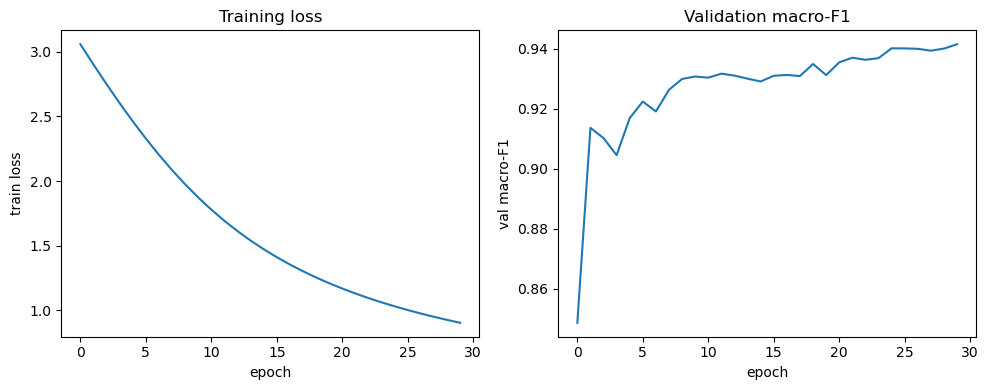

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(clf.history["train_loss"])
plt.xlabel("epoch"); plt.ylabel("train loss"); plt.title("Training loss")

plt.subplot(1, 2, 2)
plt.plot(clf.history["val_macro_f1"])
plt.xlabel("epoch"); plt.ylabel("val macro-F1"); plt.title("Validation macro-F1")

plt.tight_layout()
plt.show()


## 10. Final evaluation on the test set

In [17]:
test_pred = clf.predict(X_test)

test_acc = accuracy_score_custom(y_test, test_pred)
test_macro_f1, per_class_f1 = macro_f1_score(y_test, test_pred, n_classes)

print(f"Test accuracy : {test_acc:.4f}")
print(f"Test macro-F1 : {test_macro_f1:.4f}")

report = classification_report_custom(y_test, test_pred, IDX2LABEL, n_classes)
report.sort_values("f1")


Test accuracy : 0.9461
Test macro-F1 : 0.9454


,precision,recall,f1,support
gom_Deva,0.723684,0.550000,0.625000,100
mar_Deva,0.666667,0.780000,0.718894,100
hin_Deva,0.793388,0.960000,0.868778,100
brx_Deva,1.000000,0.820000,0.901099,100
doi_Deva,0.937500,0.900000,0.918367,100
mai_Deva,0.957895,0.910000,0.933333,100
MACRO AVG,0.948208,0.946087,0.945410,2300
san_Deva,0.908257,0.990000,0.947368,100
khasi,0.900901,1.000000,0.947867,100
npi_Deva,0.950000,0.950000,0.950000,100


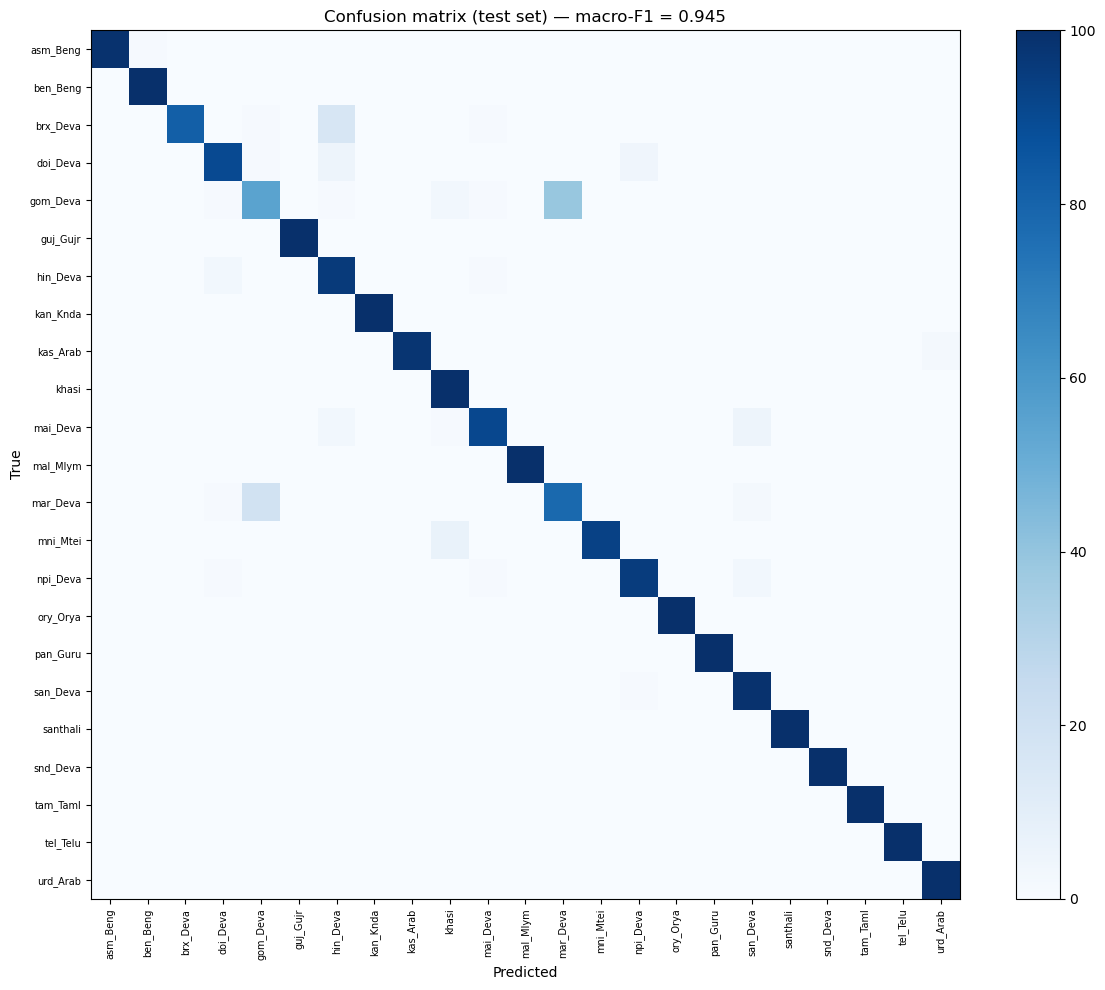

In [18]:
cm = confusion_matrix_custom(y_test, test_pred, n_classes)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_xticklabels(LABELS, rotation=90, fontsize=7)
ax.set_yticks(range(n_classes)); ax.set_yticklabels(LABELS, fontsize=7)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix (test set) — macro-F1 = {test_macro_f1:.3f}")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()


## 11. Save model artifacts

In [19]:
with open(os.path.join(ARTIFACTS_DIR, "vectorizer.pkl"), "wb") as f:
    pickle.dump({"vocab": vectorizer.vocab_, "idf": vectorizer.idf_,
                 "max_features": vectorizer.max_features, "min_df": vectorizer.min_df}, f)

with open(os.path.join(ARTIFACTS_DIR, "classifier.pkl"), "wb") as f:
    pickle.dump({"W": clf.W, "b": clf.b, "labels": LABELS,
                 "label2idx": LABEL2IDX, "idx2label": IDX2LABEL}, f)

report.to_csv(os.path.join(ARTIFACTS_DIR, "test_classification_report.csv"))
print("Saved vectorizer.pkl, classifier.pkl, and test_classification_report.csv to", ARTIFACTS_DIR)


Saved vectorizer.pkl, classifier.pkl, and test_classification_report.csv to artifacts


## 12. Inference on new text

Loads the saved artifacts and predicts the language (HF split label) of arbitrary input text.


In [24]:
def load_lid_model(artifacts_dir=ARTIFACTS_DIR):
    with open(os.path.join(artifacts_dir, "vectorizer.pkl"), "rb") as f:
        vec_state = pickle.load(f)
    with open(os.path.join(artifacts_dir, "classifier.pkl"), "rb") as f:
        clf_state = pickle.load(f)

    vec = SimpleTfidfVectorizer(max_features=vec_state["max_features"], min_df=vec_state["min_df"])
    vec.vocab_ = vec_state["vocab"]
    vec.idf_ = vec_state["idf"]

    model = SoftmaxLogisticRegression(n_features=len(vec.vocab_), n_classes=len(clf_state["labels"]),
                                       verbose=False)
    model.W = clf_state["W"]
    model.b = clf_state["b"]
    return vec, model, clf_state["idx2label"]


def predict_language(text, vec, model, idx2label, top_k=3):
    X = vec.transform([text], desc="inference")
    probs = model.predict_proba(X)[0]
    order = np.argsort(-probs)[:top_k]
    return [(idx2label[i], float(probs[i])) for i in order]


vec_loaded, model_loaded, idx2label_loaded = load_lid_model()
# for sample in [train_texts[0], val_texts[0], test_texts[0]]:
#     print(sample[:60], "->", predict_language(sample, vec_loaded, model_loaded, idx2label_loaded))

sample_text = "તારું નામ શું છે?"
# sample_text = "இங்க உக்காருங்க"
print(sample_text, "->", predict_language(sample_text, vec_loaded, model_loaded, idx2label_loaded))


તારું નામ શું છે? -> [('guj_Gujr', 0.3041190031488528), ('san_Deva', 0.046233397874349574), ('mai_Deva', 0.04200353344679062)]
